In [2]:
import pandas as pd
df = pd.read_csv("bank-full.csv",sep = ";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.shape

(45211, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["y"].value_counts(normalize=True).mul(100).round(2)

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

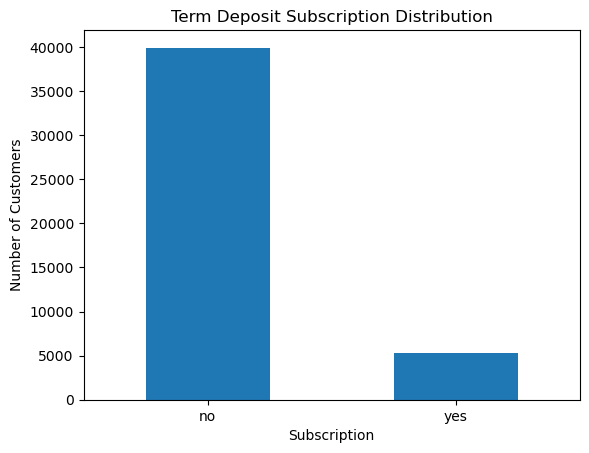

In [9]:
import matplotlib.pyplot as plt
df["y"].value_counts().plot(kind = "bar")

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [10]:
baseline_accuracy = (df["y"]=="no").mean()*100
print("Always Predict NO accuracy: ",round(baseline_accuracy,2),"%")

Always Predict NO accuracy:  88.3 %


In [11]:
baseline_Accuracy = (df["y"] == "yes").mean() * 100
print("Always Predict 'YES' Accuracy: ",round(baseline_Accuracy,2),"%")

Always Predict 'YES' Accuracy:  11.7 %


In [12]:
y_actual = df["y"]
y_pred = ["no"] *len(y_actual)
print(y_pred[:5])
print("total prediction: ",len(y_pred))

['no', 'no', 'no', 'no', 'no']
total prediction:  45211


In [13]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels = ["no","yes"]
)
print(cm)

[[39922     0]
 [ 5289     0]]


Accuracy, f1_score , confusion matrix, recoll , Precision

In [14]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(
    y_actual,
    y_pred
)
print(round(accuracy*100,2),"%")

88.3 %


precision . 

In [15]:
from sklearn.metrics import precision_score
precision = precision_score(
    y_actual,
    y_pred,
    pos_label = 'yes',
    zero_division = 0
)
print(round(precision*100,2),"%")

0.0 %


In [16]:
#recall
from sklearn.metrics import recall_score
recall = recall_score(
    y_actual,
    y_pred,
    pos_label = "yes"
    
)
print(round(recall *100,2),"%")

0.0 %


F1_Score :--   F1-score combines Precision and Recall into one number.

Remember:
- Precision tells us how often our YES predictions are correct.
- Recall tells us how many actual YES customers we found.
F1-score helps us understand both together.
2. Simple example
Imagine our model predicts YES for 100 customers.
- 80 predictions were correct.
- There were 100 actual YES customers, and our model found 80 of them.
So:
- Precision = 80%
- Recall = 80%
- F1-score = 80%
The formula is:
\[
F1 = 2 \times \frac{Precision \times Recall}{Precision+Recall}
\]

In [17]:
from sklearn.metrics import f1_score

f1_score = f1_score(
    y_actual,
    y_pred,
    pos_label = "yes",
    zero_division = 0
)
print(round(f1_score*100,2),"%")

0.0 %


Data Preparation. giving inputs and targets to data. using train test split

In [18]:
#we are removing duration column cause we dont need this column. cause this column will not give much imformation to train the model.
X = df.drop(columns=["y","duration"])
y = df["y"]

print(X.shape)
print(y.shape)

(45211, 15)
(45211,)


In [19]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(36168, 15)
(36168,)
(9043, 15)
(9043,)


In [20]:
cat_cols = X_train.select_dtypes(include="object").columns
num_cols = X_train.select_dtypes(include = "number").columns

print("Text",cat_cols)
print("NUmbers",num_cols)

Text Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object')
NUmbers Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')


In [21]:
#converting text cloumns into numbers.
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown = "ignore"
)
X_train_encoding = encoder.fit_transform(X_train[cat_cols])
X_test_encoding = encoder.transform(X_test[cat_cols])

print(len(cat_cols))
print(X_train_encoding.shape)
print(X_test_encoding.shape)

9
(36168, 44)
(9043, 44)


In [22]:
X_train[num_cols].describe()

,age,balance,day,campaign,pdays,previous
count,36168.000000,36168.00000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.892999,1365.49342,15.817961,2.763935,40.157238,0.581730
std,10.627075,3068.54350,8.331980,3.104161,100.162614,2.408766
min,18.000000,-8019.00000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,74.00000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.00000,16.000000,2.000000,-1.000000,0.000000
75%,48.000000,1430.25000,21.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.00000,31.000000,63.000000,871.000000,275.000000


In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[num_cols])
X_test_scaled = scaler.transform(X_test[num_cols])

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(36168, 6)
(9043, 6)


In [24]:
from scipy.sparse import hstack

X_train_processed = hstack([X_train_encoding,X_train_scaled])
X_test_processed = hstack([X_test_encoding,X_test_scaled])

print(X_train_processed.shape)
print(X_test_processed.shape)

(36168, 50)
(9043, 50)


# now Creating model. 1 / Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report


log_model = LogisticRegression(max_iter = 1000)

log_model.fit(X_train_processed,y_train)
log_prediction = log_model.predict(X_test_processed)

cm = confusion_matrix(
    y_test,
    log_prediction,
    labels=["no","yes"]
)
A_S = accuracy_score(
    y_test,
    log_prediction 
)
P_S = precision_score(
    y_test,
    log_prediction,
    pos_label = "yes"
)
R_S = recall_score(
    y_test,
    log_prediction,
    pos_label = "yes",
)
f1_S = f1_score(
    y_test,
    log_prediction,
    pos_label = "yes",
    zero_division = 0
)

C_R = classification_report(
    y_test,
    log_prediction,
    labels=["no","yes"],
    zero_division = 0
)
#to check the probablity of saying model "yes","NO" so here we using only class by in what class they fall.
log_probability = log_model.predict_proba(X_test_processed)

#now we are checking for the "yes" probability 
yes_probability = log_probability[:,1]    
print(pd.Series(log_prediction).value_counts())

print(cm)
print(round(A_S *100,2),"%")
print(round(P_S *100,2),"%")
print(round(R_S * 100,2),"%")
print(round(f1_S * 100,2),"%")
print(C_R)

print(log_model.classes_)
print(log_probability[:5])
print(yes_probability)

no     8758
yes     285
Name: count, dtype: int64
[[7889   96]
 [ 869  189]]
89.33 %
66.32 %
17.86 %
28.15 %
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043

['no' 'yes']
[[0.98676755 0.01323245]
 [0.97434118 0.02565882]
 [0.96420751 0.03579249]
 [0.98270109 0.01729891]
 [0.86748761 0.13251239]]
[0.01323245 0.02565882 0.03579249 ... 0.07436168 0.1167111  0.06735449]


In [28]:
#Create predictions using a custom threshold
#Previously, our model used 0.5.

#Now we'll use 0.3.

#The logic is simple:
#- Probability ≥ 0.3 → yes
#- Probability < 0.3 → no

import numpy as np
threshold = 0.3
log_prediction_03 = np.where(yes_probability >= threshold,"yes","no")

print(pd.Series(log_prediction_03).value_counts())

no     8409
yes     634
Name: count, dtype: int64


In [29]:
#calculate the evaluation metrics using our new predictions.
from sklearn.metrics import (confusion_matrix,classification_report)

cm_03 = confusion_matrix(
    y_test,
    log_prediction_03,
    labels = ["no","yes"]
)

cr_03 = classification_report(
    y_test,
    log_prediction_03,
    labels = ["no","yes"],
    zero_division = 0
)

print("Confusion_matrix: ", cm_03)
print("Classification_report: ", cr_03)

Confusion_matrix:  [[7703  282]
 [ 706  352]]
Classification_report:                precision    recall  f1-score   support

          no       0.92      0.96      0.94      7985
         yes       0.56      0.33      0.42      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.65      0.68      9043
weighted avg       0.87      0.89      0.88      9043



In [30]:
#now we are checking which threshold to choose and get maximum better model.
thresholds = [0.1,0.2,0.3,0.4,0.5]
for threshold in thresholds:
    prediction = np.where(
        yes_probability >= threshold,
        "yes",
        "no"
    )
    precision = precision_score(
        y_test,
        prediction,
        pos_label = "yes",
        zero_division = 0
    ) 
    
    recall = recall_score(
        y_test,
        prediction,
        pos_label="yes",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        prediction,
        pos_label="yes",
        zero_division = 0
    )
    print(
        f"threshold: {threshold} | "
        f"precision: {precision:.2f} | "
        f"recall: {recall:.2f} | "
        f"F1_score: {f1:.2f}"
    )

threshold: 0.1 | precision: 0.22 | recall: 0.72 | F1_score: 0.34
threshold: 0.2 | precision: 0.46 | recall: 0.44 | F1_score: 0.45
threshold: 0.3 | precision: 0.56 | recall: 0.33 | F1_score: 0.42
threshold: 0.4 | precision: 0.60 | recall: 0.25 | F1_score: 0.35
threshold: 0.5 | precision: 0.66 | recall: 0.18 | F1_score: 0.28


AUC_Score:  0.7717


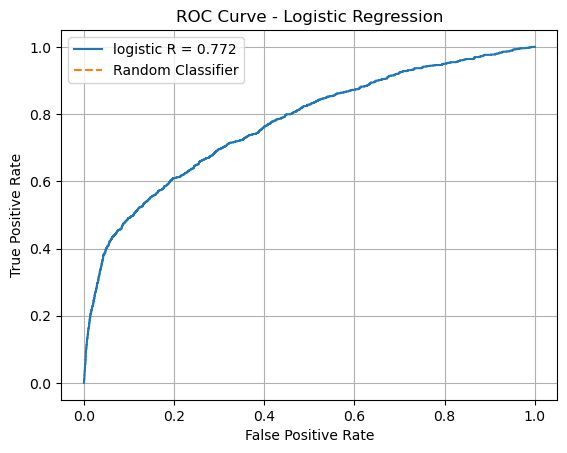

In [31]:
#Practical implementation of ROC-AUC
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
yes_probability = log_probability[:,1]
fpr,tpr,thresholds_roc = roc_curve(
    y_test,
    yes_probability,
    pos_label = "yes"
)
#Calculate AUC Score
auc_score = roc_auc_score(
    y_test,
    yes_probability
)
print("AUC_Score: ",round(auc_score,4))

plt.plot(fpr,tpr,label =f"logistic R = {auc_score:.3f}")

plt.plot(
    [0.1],
    [0.1],
    linestyle = "--",
    label = "Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()

9043
9043
9042


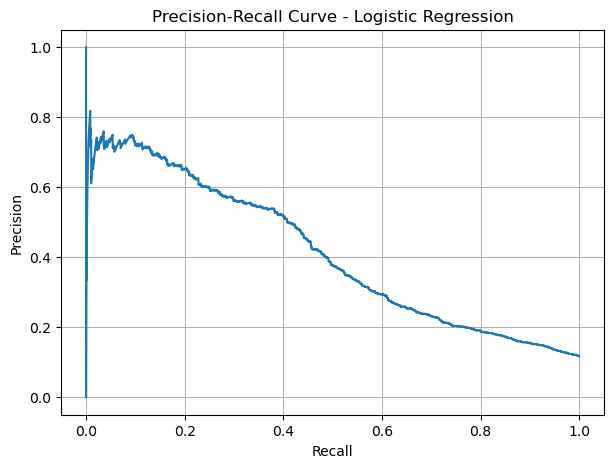

In [32]:
#Implement the Precision-Recall Curve
from sklearn.metrics import precision_recall_curve
precision,recall,pr_threshold = precision_recall_curve(
    y_test,
    yes_probability,
    pos_label = "yes"
)
print(len(precision))
print(len(recall))
print(len(pr_threshold))

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")

plt.grid()
plt.show()

In [33]:
#Average Precision (AP)  calculate one numerical score to summarize our Precision-Recall curve.
from sklearn.metrics import average_precision_score
ap_score = average_precision_score(
    y_test,
    yes_probability,
    pos_label = "yes"
)
print(round(ap_score,4))

0.4111


In [34]:
#Implement K-Fold Cross-Validation
from sklearn.model_selection import KFold
kfold = KFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
    
)
for fold,(train_index,val_index)in enumerate(
    kfold.split(X_train_processed),start = 1
):
    
    print(f"Fold {fold}")
    print("Training records:", len(train_index))
    print("Validation records:", len(val_index))
    print("----------------------")


Fold 1
Training records: 28934
Validation records: 7234
----------------------
Fold 2
Training records: 28934
Validation records: 7234
----------------------
Fold 3
Training records: 28934
Validation records: 7234
----------------------
Fold 4
Training records: 28935
Validation records: 7233
----------------------
Fold 5
Training records: 28935
Validation records: 7233
----------------------


In [35]:
#Instead of manually training and evaluating Logistic Regression five times, Scikit-learn can perform the process for us Import cross_val_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

log_model_cv = LogisticRegression(max_iter = 100)
cv_scores = cross_val_score(
    log_model_cv,
    X_train_processed,
    y_train,
    cv=kfold,
    scoring="accuracy"
)

print("Cross Validation Scores:", cv_scores)
print("Average Accuracy:", cv_scores.mean())

Cross Validation Scores: [0.88913464 0.89535527 0.89079348 0.89340523 0.89312872]
Average Accuracy: 0.8923634651352407


In [36]:
#StratifiedKFold
from sklearn.model_selection import StratifiedKFold
S_Kfold = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)
for fold, (train_index,val_index)in enumerate(
    S_Kfold.split(X_train_processed,y_train),start = 1
):
    print(f"Fold {fold}")
    print("Training distribution:")
    print(y_train.iloc[train_index].value_counts(normalize=True))

    print("Validation distribution:")
    print(y_train.iloc[val_index].value_counts(normalize=True))

    print("----------------------")

from sklearn.model_selection import cross_val_score

log_model_cv = LogisticRegression(max_iter=1000)

strat_cv_scores = cross_val_score(
    log_model_cv,
    X_train_processed,
    y_train,
    cv=S_Kfold,
    scoring="accuracy"
)

print("Stratified CV Scores:", strat_cv_scores)
print("Average Accuracy:", strat_cv_scores.mean())

Fold 1
Training distribution:
y
no     0.88301
yes    0.11699
Name: proportion, dtype: float64
Validation distribution:
y
no     0.883052
yes    0.116948
Name: proportion, dtype: float64
----------------------
Fold 2
Training distribution:
y
no     0.88301
yes    0.11699
Name: proportion, dtype: float64
Validation distribution:
y
no     0.883052
yes    0.116948
Name: proportion, dtype: float64
----------------------
Fold 3
Training distribution:
y
no     0.883044
yes    0.116956
Name: proportion, dtype: float64
Validation distribution:
y
no     0.882914
yes    0.117086
Name: proportion, dtype: float64
----------------------
Fold 4
Training distribution:
y
no     0.883014
yes    0.116986
Name: proportion, dtype: float64
Validation distribution:
y
no     0.883036
yes    0.116964
Name: proportion, dtype: float64
----------------------
Fold 5
Training distribution:
y
no     0.883014
yes    0.116986
Name: proportion, dtype: float64
Validation distribution:
y
no     0.883036
yes    0.116964


In [37]:
#Class Weight
from sklearn.linear_model import LogisticRegression
log_model_balanced = LogisticRegression(
    max_iter = 100,
    class_weight = "balanced"
)
log_model_balanced.fit(X_train_processed,y_train)
log_model_balanced_prediction = log_model_balanced.predict(X_test_processed)

from sklearn.metrics import (confusion_matrix, classification_report,accuracy_score)

print("confusion_matrix")
print(confusion_matrix(
    y_test,
    log_model_balanced_prediction,
    labels = ["no","yes"]
))

print("/nClassification_report")
print(classification_report(
    y_test,
    log_model_balanced_prediction,
    
))

print("Accuracy")
print(accuracy_score(
    y_test,
    log_model_balanced_prediction
))
      

confusion_matrix
[[6166 1819]
 [ 398  660]]
/nClassification_report
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043

Accuracy
0.7548379962401858


In [38]:
#RandomOverSampler
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state = 42)
X_train_over, y_train_over = ros.fit_resample(
    X_train_processed,
    y_train
)
print("Before Oversampling:")
print(y_train.value_counts())

print("\nAfter Oversampling:")
print(y_train_over.value_counts())

Before Oversampling:
y
no     31937
yes     4231
Name: count, dtype: int64

After Oversampling:
y
no     31937
yes    31937
Name: count, dtype: int64


In [39]:
#Train Logistic Regression on Oversampled Data
#Now let's see whether oversampling improves our model.
from sklearn.linear_model import LogisticRegression
log_model_over = LogisticRegression(
    max_iter = 100
)
log_model_over.fit(X_train_over,y_train_over)
over_prediction = log_model_over.predict(X_test_processed)

#now evaluate the model.
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)

print("Confusion_matrix: ",confusion_matrix(y_test,over_prediction,labels = ["no","yes"]))
print("Classification_report: ",classification_report(y_test,over_prediction))
print("Accuracy_score: ",accuracy_score(y_test,over_prediction))

Confusion_matrix:  [[6182 1803]
 [ 398  660]]
Classification_report:                precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043

Accuracy_score:  0.7566073205794537


In [40]:
#Train Logistic Regression on Undersampled Data
#Now let's see whether Undersampling improves our model.
from sklearn.linear_model import LogisticRegression
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state = 42)
X_train_under,y_train_under = rus.fit_resample(X_train_processed,y_train)

print("Before Undersampling:")
print(y_train.value_counts())
print("\nAfter Undersampling:")
print(y_train_under.value_counts())

print("\n---------------------------------------------------------------------------------")

log_model_under = LogisticRegression(max_iter = 100)
log_model_under.fit(X_train_under,y_train_under)
under_prediction = log_model_under.predict(X_test_processed)

from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)
print("Confusion_matrix: ",confusion_matrix(y_test,under_prediction,labels = ["no","yes"]))
print("Classification_report: ",classification_report(y_test,under_prediction))
print("Accuracy_score: ",accuracy_score(y_test,under_prediction))


Before Undersampling:
y
no     31937
yes     4231
Name: count, dtype: int64

After Undersampling:
y
no     4231
yes    4231
Name: count, dtype: int64

---------------------------------------------------------------------------------
Confusion_matrix:  [[6260 1725]
 [ 398  660]]
Classification_report:                precision    recall  f1-score   support

          no       0.94      0.78      0.86      7985
         yes       0.28      0.62      0.38      1058

    accuracy                           0.77      9043
   macro avg       0.61      0.70      0.62      9043
weighted avg       0.86      0.77      0.80      9043

Accuracy_score:  0.765232776733385


In [41]:
##Smote
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\n---------------------------------------------------------------------------------")

log_model_smote = LogisticRegression(max_iter = 100)
log_model_smote.fit(X_train_smote,y_train_smote)
smote_prediction = log_model_smote.predict(X_test_processed)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score)
print("Confusion_matrix: ",confusion_matrix(y_test,smote_prediction,labels = ["no","yes"]))
print("Classification_report: ",classification_report(y_test,smote_prediction))
print("Accuracy_score: ",accuracy_score(y_test,smote_prediction))

Before SMOTE:
y
no     31937
yes     4231
Name: count, dtype: int64

After SMOTE:
y
no     31937
yes    31937
Name: count, dtype: int64

---------------------------------------------------------------------------------
Confusion_matrix:  [[6081 1904]
 [ 387  671]]
Classification_report:                precision    recall  f1-score   support

          no       0.94      0.76      0.84      7985
         yes       0.26      0.63      0.37      1058

    accuracy                           0.75      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.75      0.79      9043

Accuracy_score:  0.7466548711710715


In [42]:
## KNN Algorithms

In [43]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score

knn_model = KNeighborsClassifier(n_neighbors = 3)

knn_model.fit(X_train_processed,y_train)

knn_model_prediction = knn_model.predict(X_test_processed)

print(knn_model_prediction[:10])

print("confusion_matrix:\n",confusion_matrix(y_test,knn_model_prediction))
print("\nClassification_report:\n",classification_report(y_test,knn_model_prediction))
print("\naccuracy_score\n",accuracy_score(y_test,knn_model_prediction))

['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']
confusion_matrix:
 [[7719  266]
 [ 802  256]]

Classification_report:
               precision    recall  f1-score   support

          no       0.91      0.97      0.94      7985
         yes       0.49      0.24      0.32      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.60      0.63      9043
weighted avg       0.86      0.88      0.86      9043


accuracy_score
 0.8818976003538649


In [44]:
#test different k values like 3,5,7,9,11 all one time.
from sklearn.metrics import f1_score
k_values = [3,5,7,9,11]
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(X_train_processed,y_train)
    prediction = knn.predict(X_test_processed)
    score = f1_score(y_test,prediction,pos_label = "yes")

    print(f"k = k{k},f1_score = {score:.4f}")

k = k3,f1_score = 0.3241
k = k5,f1_score = 0.2911
k = k7,f1_score = 0.2973
k = k9,f1_score = 0.2838
k = k11,f1_score = 0.2853


In [ ]:
#decision Tree model

In [56]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state = 42)
dt_model.fit(X_train_processed,y_train)
dt_prediction = dt_model.predict(X_test_processed)
print(dt_prediction[:10])

from sklearn.metrics import (confusion_matrix, classification_report,accuracy_score)
print(confusion_matrix(y_test, dt_prediction))
print(classification_report(y_test,dt_prediction))
print(accuracy_score(y_test,dt_prediction))


['no' 'no' 'no' 'no' 'no' 'no' 'yes' 'yes' 'yes' 'no']
[[7188  797]
 [ 714  344]]
              precision    recall  f1-score   support

          no       0.91      0.90      0.90      7985
         yes       0.30      0.33      0.31      1058

    accuracy                           0.83      9043
   macro avg       0.61      0.61      0.61      9043
weighted avg       0.84      0.83      0.84      9043

0.8329094327103838


In [64]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

depth_values = [3, 5, 7, 10, None]

dt_results = []

for depth in depth_values:

    # Create model
    dt_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train model
    dt_model.fit(X_train_processed, y_train)

    # Predictions
    dt_prediction = dt_model.predict(X_test_processed)

    # Evaluation
    accuracy = accuracy_score(y_test, dt_prediction)
    precision = precision_score(y_test, dt_prediction, pos_label="yes")
    recall = recall_score(y_test, dt_prediction, pos_label="yes")
    f1 = f1_score(y_test, dt_prediction, pos_label="yes")

    # Store results
    dt_results.append({
        "max_depth": depth,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

import pandas as pd

dt_results_df = pd.DataFrame(dt_results)
print(dt_results_df.round(4))

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    train_score = model.score(X_train_processed, y_train)
    test_score = model.score(X_test_processed, y_test)

    print(
        f"Depth: {depth}, "
        f"Training Accuracy: {train_score:.4f}, "
        f"Testing Accuracy: {test_score:.4f}"
    )


   max_depth  accuracy  precision  recall  f1_score
0        3.0    0.8932     0.6655  0.1749    0.2769
1        5.0    0.8927     0.6947  0.1484    0.2445
2        7.0    0.8930     0.6148  0.2278    0.3324
3       10.0    0.8915     0.5980  0.2221    0.3239
4        NaN    0.8329     0.3015  0.3251    0.3129
Depth: 3, Training Accuracy: 0.8937, Testing Accuracy: 0.8932
Depth: 5, Training Accuracy: 0.8946, Testing Accuracy: 0.8927
Depth: 7, Training Accuracy: 0.8996, Testing Accuracy: 0.8930
Depth: 10, Training Accuracy: 0.9080, Testing Accuracy: 0.8915
Depth: None, Training Accuracy: 1.0000, Testing Accuracy: 0.8329


In [65]:
#Random_forest model

In [69]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42,
    n_jobs = -1
)

rf_model.fit(X_train_processed,y_train)
rf_prediction = rf_model.predict(X_test_processed)

print("Confusion_matrix\n",confusion_matrix(y_test,rf_prediction))
print("\nClassification_report\n",classification_report(y_test,rf_prediction))
print("\nAccuracy_score\n",accuracy_score(y_test,rf_prediction))

Confusion_matrix
 [[7832  153]
 [ 809  249]]

Classification_report
               precision    recall  f1-score   support

          no       0.91      0.98      0.94      7985
         yes       0.62      0.24      0.34      1058

    accuracy                           0.89      9043
   macro avg       0.76      0.61      0.64      9043
weighted avg       0.87      0.89      0.87      9043


Accuracy_score
 0.8936193741015149


In [70]:
## Naive Bayes model


In [72]:
from sklearn.naive_bayes import GaussianNB
## import sparse matrix checker
from scipy.sparse import issparse
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
# Convert sparse data to dense, if necessary
if issparse(X_train_processed):
    X_train_nb = X_train_processed.toarray()
    X_test_nb = X_test_processed.toarray()
else:
    X_train_nb = X_train_processed
    X_test_nb = X_test_processed

##create model:
nb_model = GaussianNB()
nb_model.fit(X_train_nb,y_train)
nb_prediction = nb_model.predict(X_test_nb)

# Evaluate model
print("Confusion Matrix:\n",
      confusion_matrix(y_test, nb_prediction))

print("\nClassification Report:\n",
      classification_report(y_test, nb_prediction))

print("\nAccuracy Score:",
      accuracy_score(y_test, nb_prediction))

Confusion Matrix:
 [[7152  833]
 [ 567  491]]

Classification Report:
               precision    recall  f1-score   support

          no       0.93      0.90      0.91      7985
         yes       0.37      0.46      0.41      1058

    accuracy                           0.85      9043
   macro avg       0.65      0.68      0.66      9043
weighted avg       0.86      0.85      0.85      9043


Accuracy Score: 0.8451841203140551


In [73]:
##Support vector machine (SVM)

In [76]:
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
svm_model = LinearSVC(
    random_state = 42,
    max_iter = 5000
)
svm_model.fit(X_train_processed,y_train)
svm_prediction = svm_model.predict(X_test_processed)

print("Confusion_matrix\n",confusion_matrix(y_test,svm_prediction))
print("\nClassification Report:\n",classification_report(y_test, svm_prediction))
print("\nAccuracy Score:",accuracy_score(y_test, svm_prediction))

Confusion_matrix
 [[7879  106]
 [ 860  198]]

Classification Report:
               precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.65      0.19      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.59      0.62      9043
weighted avg       0.87      0.89      0.87      9043


Accuracy Score: 0.893177043016698


In [77]:
# Gradient Boosting model

In [87]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
gb_model = GradientBoostingClassifier(
    n_estimators = 100,
    learning_rate = 0.1,
    random_state = 42,
    max_depth = 3
)
gb_model.fit(X_train_processed,y_train)
gb_prediction = gb_model.predict(X_test_processed)

print("Confusion_matrix\n",confusion_matrix(y_test,gb_prediction))
print("\nClassification_report\n",classification_report(y_test,gb_prediction))
print("\nAccuracy_score",accuracy_score(y_test,gb_prediction))
      

Confusion_matrix
 [[7876  109]
 [ 847  211]]

Classification_report
               precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.66      0.20      0.31      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.59      0.62      9043
weighted avg       0.87      0.89      0.87      9043


Accuracy_score 0.8942828707287405


In [88]:
## XG BOOST

In [93]:
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix ,classification_report,accuracy_score

#Convert target labels into numbers
label_encoder = LabelEncoder()
y_train_xgb = label_encoder.fit_transform(y_train)

xgb_model = XGBClassifier(
    n_estimators = 100,
    max_depth = 3,
    learning_rate = 0.1,
    subsample = 0.8,
    colsample_bytree = 0.8,
    objective = "binary:logistic",
    eval_metric = "logloss",
    tree_method = "hist",
    random_state = 42,
    n_jobs = -1
    
)
# train the model
xgb_model.fit(X_train_processed, y_train_xgb)

#  Make predictions
xgb_prediction_encoded = xgb_model.predict(X_test_processed)

#Convert predictions back to yes/no
xgb_prediction = label_encoder.inverse_transform(
    xgb_prediction_encoded
)

#Evaluate the model
print("Confusion Matrix:\n",
      confusion_matrix(y_test, xgb_prediction))

print("\nClassification Report:\n",
      classification_report(y_test, xgb_prediction))

print("\nAccuracy Score:",
      accuracy_score(y_test, xgb_prediction))

Confusion Matrix:
 [[7882  103]
 [ 849  209]]

Classification Report:
               precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.67      0.20      0.31      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.59      0.62      9043
weighted avg       0.88      0.89      0.87      9043


Accuracy Score: 0.8947252018135574


In [103]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score
from sklearn.tree import DecisionTreeClassifier
f1_scorer = make_scorer(f1_score, pos_label="yes")
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5],
    "criterion": ["gini", "entropy"]
}
strat_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=strat_kfold,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
dt_grid.fit(X_train_processed,y_train)
print("Best Parameters:", dt_grid.best_params_)

print("Best CV F1 Score:", dt_grid.best_score_)
# Get the best trained model
dt_best_model = dt_grid.best_estimator_

# Check its depth
print("Best Tree Depth:", dt_best_model.get_depth())

# Check number of leaves
print("Number of Leaves:", dt_best_model.get_n_leaves())

# Make predictions
dt_grid_prediction = dt_best_model.predict(X_test_processed)

# Evaluate the model
print("\nConfusion Matrix:\n",
      confusion_matrix(y_test, dt_grid_prediction))

print("\nClassification Report:\n",
      classification_report(y_test, dt_grid_prediction))

print("\nAccuracy:",
      accuracy_score(y_test, dt_grid_prediction))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV F1 Score: 0.3416005545739417
Best Tree Depth: 37
Number of Leaves: 2537

Confusion Matrix:
 [[7565  420]
 [ 748  310]]

Classification Report:
               precision    recall  f1-score   support

          no       0.91      0.95      0.93      7985
         yes       0.42      0.29      0.35      1058

    accuracy                           0.87      9043
   macro avg       0.67      0.62      0.64      9043
weighted avg       0.85      0.87      0.86      9043


Accuracy: 0.8708393232334403


In [104]:
from sklearn.model_selection import RandomizedSearchCV
param_distributions = {
    "max_depth": [None, 5, 7, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"]
}
dt_random = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=20,
    scoring=f1_scorer,
    cv=strat_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
dt_random.fit(X_train_processed, y_train)
print("Best Parameters:", dt_random.best_params_)

print("Best CV F1 Score:", dt_random.best_score_)
dt_random_best = dt_random.best_estimator_

random_prediction = dt_random_best.predict(X_test_processed)

print("Confusion Matrix:\n",
      confusion_matrix(y_test, random_prediction))

print("\nClassification Report:\n",
      classification_report(y_test, random_prediction))

print("\nAccuracy:",
      accuracy_score(y_test, random_prediction))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'min_samples_split': 20, 'min_samples_leaf': 10, 'max_depth': None, 'criterion': 'gini'}
Best CV F1 Score: 0.34395111855153193
Confusion Matrix:
 [[7738  247]
 [ 775  283]]

Classification Report:
               precision    recall  f1-score   support

          no       0.91      0.97      0.94      7985
         yes       0.53      0.27      0.36      1058

    accuracy                           0.89      9043
   macro avg       0.72      0.62      0.65      9043
weighted avg       0.87      0.89      0.87      9043


Accuracy: 0.8869844078292602


In [105]:
dt_random_best
print(type(X_train_processed))
print(X_train_processed.shape)

<class 'scipy.sparse._coo.coo_matrix'>
(36168, 50)


In [109]:
import pandas as pd
import numpy as np
# Extract feature importance
importance = dt_random_best.feature_importances_
# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature_index":np.arange(len(importance)),
    "Importance": importance
})
# Sort features from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print(importance_df.head(15))

    Feature_index  Importance
42             42    0.235997
45             45    0.144256
44             44    0.136003
46             46    0.101872
48             48    0.057070
47             47    0.034307
27             27    0.028069
34             34    0.025818
35             35    0.024303
38             38    0.022351
22             22    0.021276
39             39    0.015870
28             28    0.015709
36             36    0.010480
37             37    0.010411


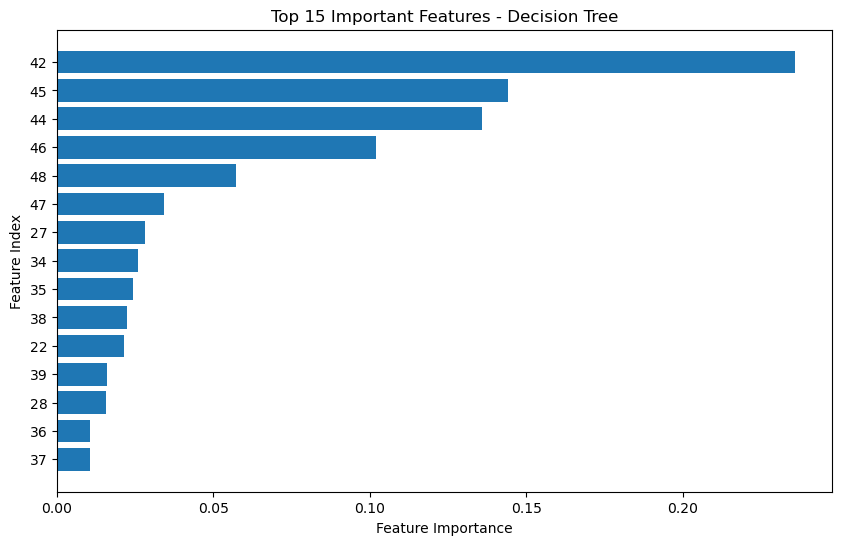

In [111]:
import matplotlib.pyplot as plt

# Select top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature_index"].astype(str),
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature Index")
plt.title("Top 15 Important Features - Decision Tree")

plt.show()

In [112]:
[name for name, obj in globals().items()
 if callable(getattr(obj, "get_feature_names_out", None))]

['OneHotEncoder',
 'encoder',
 'StandardScaler',
 'scaler',
 'RandomOverSampler',
 'ros',
 'RandomUnderSampler',
 'rus',
 'SMOTE',
 'smote']

In [113]:
encoded_feature_names = encoder.get_feature_names_out()

print(encoded_feature_names)
print("Total encoded features:", len(encoded_feature_names))


['job_admin.' 'job_blue-collar' 'job_entrepreneur' 'job_housemaid'
 'job_management' 'job_retired' 'job_self-employed' 'job_services'
 'job_student' 'job_technician' 'job_unemployed' 'job_unknown'
 'marital_divorced' 'marital_married' 'marital_single' 'education_primary'
 'education_secondary' 'education_tertiary' 'education_unknown'
 'default_no' 'default_yes' 'housing_no' 'housing_yes' 'loan_no'
 'loan_yes' 'contact_cellular' 'contact_telephone' 'contact_unknown'
 'month_apr' 'month_aug' 'month_dec' 'month_feb' 'month_jan' 'month_jul'
 'month_jun' 'month_mar' 'month_may' 'month_nov' 'month_oct' 'month_sep'
 'poutcome_failure' 'poutcome_other' 'poutcome_success' 'poutcome_unknown']
Total encoded features: 44


In [117]:
print("Numerical feature names:")

print(scaler.feature_names_in_)
print("Number of numerical features:", scaler.n_features_in_)

Numerical feature names:
['age' 'balance' 'day' 'campaign' 'pdays' 'previous']
Number of numerical features: 6


In [119]:
import numpy as np
import pandas as pd

# Get 44 categorical feature names
categorical_features = encoder.get_feature_names_out()

# Get 6 numerical feature names
numerical_features = scaler.feature_names_in_

# Combine names in the same order as X_train_processed
all_feature_names = np.concatenate([
    categorical_features,
    numerical_features
])

# Extract importance scores
importance = dt_random_best.feature_importances_

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 15
print(importance_df.head(15))


             Feature  Importance
0   poutcome_success    0.235997
1            balance    0.144256
2                age    0.136003
3                day    0.101872
4              pdays    0.057070
5           campaign    0.034307
6    contact_unknown    0.028069
7          month_jun    0.025818
8          month_mar    0.024303
9          month_oct    0.022351
10       housing_yes    0.021276
11         month_sep    0.015870
12         month_apr    0.015709
13         month_may    0.010480
14         month_nov    0.010411


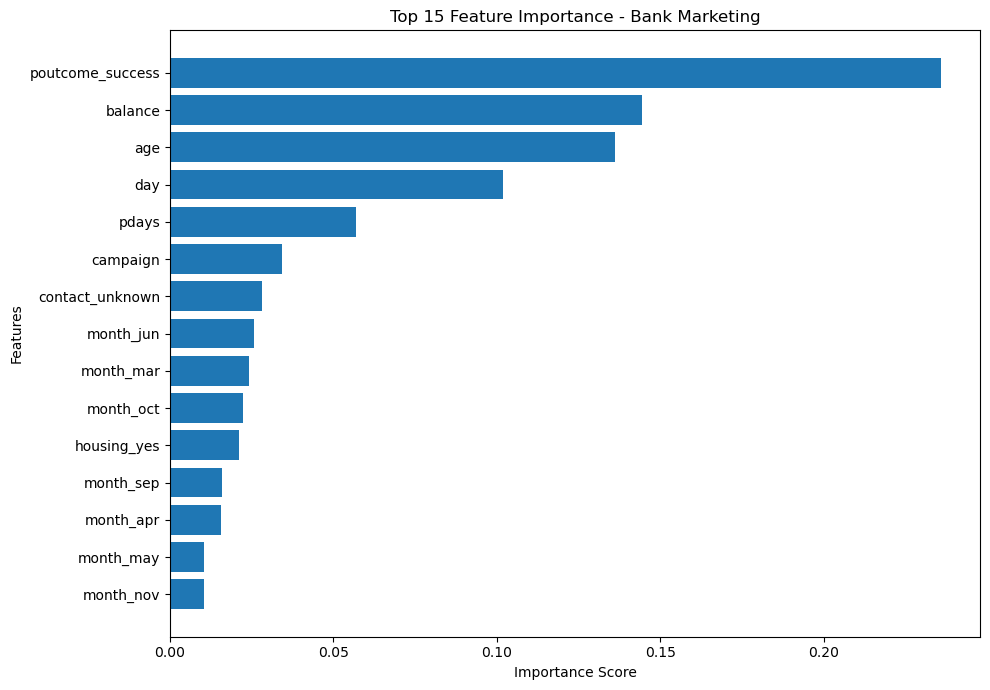

In [120]:
import matplotlib.pyplot as plt

# Select top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

# Create chart
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance - Bank Marketing")

plt.tight_layout()
plt.show()

In [125]:
## Feature selection

In [126]:
from sklearn.feature_selection import SelectFromModel
selector = SelectFromModel(
    estimator = dt_random_best,
    threshold = 0.1,
    prefit = "True"
)
X_train_selected = selector.transform(X_train_processed)
X_test_selected = selector.transform(X_test_processed)

selected_mask = selector.get_support()
selected_features = all_feature_names[selected_mask]

print("Selected Features:")
print(selected_features)

print("\nNumber of selected features:", len(selected_features))

print("Original features:", X_train_processed.shape[1])

print("Reduced features:", X_train_selected.shape[1])

Selected Features:
['poutcome_success' 'age' 'balance' 'day']

Number of selected features: 4
Original features: 50
Reduced features: 4


In [128]:
from sklearn.linear_model import LogisticRegression

log_selected_model = LogisticRegression(max_iter=1000)
log_selected_model.fit(X_train_selected, y_train)
log_model.fit(X_train_processed, y_train)
selected_prediction = log_selected_model.predict(X_test_selected)
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

print("Confusion Matrix:\n",
      confusion_matrix(y_test, selected_prediction))

print("\nClassification Report:\n",
      classification_report(y_test, selected_prediction))

print("\nAccuracy:",
      accuracy_score(y_test, selected_prediction))

print("\nF1 Score (yes):",
      f1_score(y_test, selected_prediction, pos_label="yes"))

Confusion Matrix:
 [[7877  108]
 [ 859  199]]

Classification Report:
               precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.65      0.19      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.59      0.62      9043
weighted avg       0.87      0.89      0.87      9043


Accuracy: 0.8930664602454937

F1 Score (yes): 0.2915750915750916
